# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

### [Bài 9] Trả lời Task 1: các thành phần của bài toán tìm kiếm

Bàn cờ là mảng NumPy `rows × cols` (mặc định 6 × 7) như ô mẫu của đề: ô trống `0`, quân đỏ `1` (Max, đi trước), quân
vàng `-1` (Min). Hàng 0 ở trên cùng, hàng `rows - 1` là hàng đáy.

| Thành phần | Định nghĩa |
| :--- | :--- |
| **Trạng thái** | Bộ (bàn cờ, người đến lượt, số nước đã đi). Khác Connect 4 thường, người đến lượt không suy ra được từ số quân vì nước "mean" chỉ chuyển quân chứ không thêm quân, nên phải lưu riêng. Số nước đã đi dùng cho giới hạn số nước bên dưới. |
| **Trạng thái ban đầu** | Bàn trống, đỏ (`1`) đến lượt, số nước đã đi bằng 0. |
| **Hành động** | Hai loại. (1) Thả quân `('drop', c)`: thả một quân của mình vào cột `c` chưa đầy. (2) Nước mean `('mean', c_from, c_to)`: lấy quân của đối thủ đang nằm ở hàng đáy cột `c_from`, rồi thả quân đó (vẫn là quân của đối thủ) vào cột `c_to` còn chỗ sau khi đã lấy quân ra; `c_to` có thể trùng `c_from`. Nếu hàng đáy không có quân nào của đối thủ thì không có nước mean. |
| **Mô hình chuyển trạng thái** `result(s, a)` | Thả quân: quân rơi xuống ô trống thấp nhất của cột. Nước mean: bỏ quân ở đáy cột `c_from`, mọi quân phía trên trong cột đó rơi xuống một ô, sau đó quân vừa lấy rơi xuống ô trống thấp nhất của cột `c_to`. Sau mỗi nước, lượt chuyển sang đối thủ và số nước đã đi tăng 1. Hàm trả về trạng thái mới, không sửa trạng thái cũ. |
| **Kiểm tra kết thúc** `terminal(s)` | Ván kết thúc khi (a) có 4 quân cùng màu liên tiếp theo hàng, cột hoặc đường chéo; (b) bàn đầy, như Connect 4 thường; hoặc (c) đạt giới hạn số nước. Vì nước mean làm quân rơi xuống, nó có thể tạo 4 quân liên tiếp cho bất kỳ bên nào, nên sau mỗi nước phải kiểm tra cả hai bên chứ không chỉ người vừa đi. |
| **Lợi ích** `utility(s, player)` | `+1` nếu `player` có 4 quân liên tiếp còn đối thủ thì không; `-1` nếu ngược lại; `0` nếu hòa (bàn đầy, đạt giới hạn số nước, hoặc cả hai bên cùng có 4 quân); `None` nếu ván chưa kết thúc. |

**Những điểm đề chưa nói rõ và quy ước được chọn:**
- Cả hai bên cùng có 4 quân sau một nước: chỉ xảy ra với nước mean, khi quân rơi xuống nối hàng cho cả hai bên. Đề
  không quy định; quy ước ở đây là hòa, để luật đối xứng giữa hai bên.
- Ván có thể kéo dài vô hạn: nước mean không thêm quân, nên hai bên có thể chuyển quân qua lại mãi mà bàn không bao
  giờ đầy. Vì vậy thêm giới hạn số nước `max_moves`, mặc định `2 × rows × cols` (84 nước với bàn 6 × 7, gấp đôi số
  nước cần để lấp đầy bàn); đạt giới hạn mà chưa ai thắng thì hòa.
- Nước mean trả quân về đúng cột cũ (`c_to = c_from`): hợp lệ theo đề ("any column"). Quân bị lấy chuyển từ đáy lên
  đỉnh cột; nếu cột chỉ có đúng quân đó thì bàn không đổi và nước này tương đương bỏ lượt.
- Các hàm `actions`, `result`, `terminal`, `utility` sẽ cài đặt theo đúng định nghĩa này ở Task 2 (ngày 2).

How big is the state space? Give an estimate and explain it.

### [Bài 9] Trả lời: kích thước không gian trạng thái

- Cấu hình một cột: trọng lực giữ mọi quân sát đáy, kể cả sau nước mean (quân phía trên rơi xuống lấp chỗ trống).
  Cột có $h$ quân có $2^h$ cách tô màu, nên mỗi cột có $\sum_{h=0}^{rows} 2^h = 2^{rows+1} - 1$ cấu hình (127 với 6 hàng)
  và toàn bàn có nhiều nhất $127^7 \approx 5{,}33 \times 10^{14}$ cách xếp quân, cùng cận đã dùng ở Bài 8.
- Connect 4 thường: đỏ luôn đi trước và mỗi nước thêm đúng một quân, nên số quân đỏ $R$ và vàng $Y$ luôn thỏa
  $R - Y \in \{0, 1\}$, và người đến lượt suy ra được từ số quân. Ô dưới đếm chính xác số bàn thỏa điều kiện này:
  khoảng $7{,}07 \times 10^{13}$. Để so sánh, số thế hợp lệ chính xác của Connect 4 (đã loại các thế không thể xảy ra như
  đi tiếp sau khi đã thắng) là 4 531 985 219 092, khoảng $4{,}5 \times 10^{12}$ (theo trang
  [Connect Four trên Wikipedia](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)).
- Mean Connect 4: nước mean không đổi số quân nhưng vẫn chuyển lượt, nên $R$ và $Y$ không còn ràng buộc (một bên có
  thể dùng nước mean nhiều lượt liền trong khi bên kia thả quân), và người đến lượt phải lưu riêng. Cận trên là
  $2 \times 127^7 \approx 1{,}07 \times 10^{15}$, gấp khoảng 15 lần cận của Connect 4 tính cùng cách. Nếu tính cả số nước
  đã đi (cho giới hạn số nước) thì nhân thêm tối đa `max_moves + 1` lần.
- Cả hai cận đều đếm dư những bàn không thể xảy ra, ví dụ bàn mà cả hai bên đều đã có 4 quân liên tiếp từ trước.

Ô dưới tính các cận này cho nhiều kích thước bàn để thấy tỷ lệ giữa hai trò chơi tăng theo kích thước.

In [1]:
# [Bài 9] Ước lượng không gian trạng thái: Connect 4 thường và Mean Connect 4 theo kích thước bàn.
from math import comb
import pandas as pd

def boards_by_color_count(rows, cols):
    # Số bàn (mọi cột là chồng quân sát đáy) theo cặp (số quân đỏ R, số quân vàng Y).
    column = {}
    for height in range(rows + 1):
        for red in range(height + 1):
            key = (red, height - red)
            column[key] = column.get(key, 0) + comb(height, red)
    total = {(0, 0): 1}
    for _ in range(cols):
        merged = {}
        for (r1, y1), a in total.items():
            for (r2, y2), b in column.items():
                key = (r1 + r2, y1 + y2)
                merged[key] = merged.get(key, 0) + a * b
        total = merged
    return total

rows_out = []
for rows, cols in [(4, 4), (4, 5), (5, 6), (6, 7)]:
    counts = boards_by_color_count(rows, cols)
    all_boards = sum(counts.values())
    assert all_boards == (2 ** (rows + 1) - 1) ** cols
    connect4 = sum(v for (red, yellow), v in counts.items() if red - yellow in (0, 1))
    mean = 2 * all_boards
    rows_out.append({'Bàn (hàng × cột)': f'{rows} × {cols}', 'Cấu hình mỗi cột': 2 ** (rows + 1) - 1,
                     'Mọi cách xếp quân': f'{all_boards:.3e}',
                     'Connect 4 (R - Y ∈ {0, 1})': f'{connect4:.3e}',
                     'Mean Connect 4 (× 2 người đến lượt)': f'{mean:.3e}',
                     'Mean / Connect 4': round(mean / connect4, 1)})
display(pd.DataFrame(rows_out))

,Bàn (hàng × cột),Cấu hình mỗi cột,Mọi cách xếp quân,"Connect 4 (R - Y ∈ {0, 1})",Mean Connect 4 (× 2 người đến lượt),Mean / Connect 4
0,4 × 4,31,9.235e+05,2.018e+05,1.847e+06,9.2
1,4 × 5,31,2.863e+07,5.622e+06,5.726e+07,10.2
2,5 × 6,63,6.252e+10,9.919e+09,1.250e+11,12.6
3,6 × 7,127,5.329e+14,7.073e+13,1.066e+15,15.1


How big is the game tree that minimax search will go through? Give an estimate and explain it.

### [Bài 9] Trả lời: kích thước cây trò chơi mà Minimax phải duyệt

- Connect 4 thường (Bài 8): mỗi nút có tối đa 7 nước, độ sâu không quá 42, nên cây có nhiều nhất
  $\sum_{d=0}^{42} 7^d \approx 3{,}64 \times 10^{35}$ nút.
- Hệ số phân nhánh của Mean Connect 4: số nước = số cột chưa đầy (tối đa `cols`) cộng (số quân đối thủ ở hàng đáy,
  tối đa `cols`) × (số cột đích, tối đa `cols`). Vậy $b \le cols + cols^2 = 56$ với bàn 6 × 7, lớn nhất khi hàng đáy
  toàn quân đối thủ; đầu ván hàng đáy còn trống nên $b$ nhỏ hơn nhiều.
- Độ sâu: nước mean không thêm quân nên ván không tự kết thúc sau 42 nước. Không có giới hạn số nước thì cây vô hạn
  (có chu trình); với giới hạn `max_moves` $= L$, cây có nhiều nhất $\sum_{d=0}^{L} 56^d$ nút.
- Cây đếm theo chuỗi nước đi: cùng một thế cờ có thể xuất hiện ở nhiều nút, và ở Mean Connect 4 còn có thể lặp lại
  chính nó trên cùng một nhánh (đi tới đi lui), nên số nút trùng lặp nhiều hơn hẳn Connect 4 thường.

Ô dưới so sánh các cận trên theo $\log_{10}$ (số chữ số của số nút).

In [2]:
# [Bài 9] Cận trên kích thước cây trò chơi (log10 số nút) cho bàn 6 × 7.
from math import log10

def tree_upper_bound(branching, depth):
    # Số nút tối đa của cây có hệ số phân nhánh `branching` và độ sâu `depth`: tổng branching^d với d = 0..depth.
    return (branching ** (depth + 1) - 1) // (branching - 1)

ROWS, COLS = 6, 7
tree_rows = [{'Trò chơi': 'Connect 4', 'Hệ số phân nhánh tối đa': COLS, 'Độ sâu tối đa': ROWS * COLS,
              'log10(số nút)': round(log10(tree_upper_bound(COLS, ROWS * COLS)), 1)}]
for limit in (ROWS * COLS, 2 * ROWS * COLS, 3 * ROWS * COLS):
    tree_rows.append({'Trò chơi': f'Mean Connect 4, max_moves = {limit}', 'Hệ số phân nhánh tối đa': COLS + COLS ** 2,
                      'Độ sâu tối đa': limit, 'log10(số nút)': round(log10(tree_upper_bound(COLS + COLS ** 2, limit)), 1)})
tree_table = pd.DataFrame(tree_rows)
display(tree_table)
print('Cùng độ sâu 42, cây Mean Connect 4 lớn hơn Connect 4 khoảng 10 mũ',
      round(tree_table.loc[1, 'log10(số nút)'] - tree_table.loc[0, 'log10(số nút)'], 1), 'lần.')

,Trò chơi,Hệ số phân nhánh tối đa,Độ sâu tối đa,log10(số nút)
0,Connect 4,7,42,35.6
1,"Mean Connect 4, max_moves = 42",56,42,73.4
2,"Mean Connect 4, max_moves = 84",56,84,146.9
3,"Mean Connect 4, max_moves = 126",56,126,220.3


Cùng độ sâu 42, cây Mean Connect 4 lớn hơn Connect 4 khoảng 10 mũ 37.8 lần.


**[Bài 9] Nhận xét: so với Connect 4 thường.**
- Không gian trạng thái lớn hơn khoảng 15 lần với bàn 6 × 7 (và tỷ lệ tăng theo kích thước bàn, từ 9,2 lần ở bàn
  4 × 4), vì mất ràng buộc về chênh lệch số quân và phải lưu người đến lượt. Mức tăng này vừa phải so với cây trò chơi.
- Cây trò chơi lớn hơn rất nhiều: cùng độ sâu 42 đã lớn hơn khoảng $10^{38}$ lần do hệ số phân nhánh tới 56 thay vì
  7, và với giới hạn mặc định 84 nước thì khoảng $10^{147}$ nút. Minimax duyệt hết cây hoàn toàn không khả thi; cần cắt
  tỉa Alpha-Beta, giới hạn độ sâu kèm heuristic hoặc Monte Carlo (Task 3-4, ngày 2-3).
- Vì một thế cờ có thể lặp lại nhiều lần trong cây, lưu các thế đã duyệt (bảng chuyển vị) có lợi hơn hẳn so với Connect 4
  thường. Hệ số phân nhánh thực tế (thấp hơn cận 56) sẽ đo bằng các ván ngẫu nhiên ở ngày 2.

## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [3]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

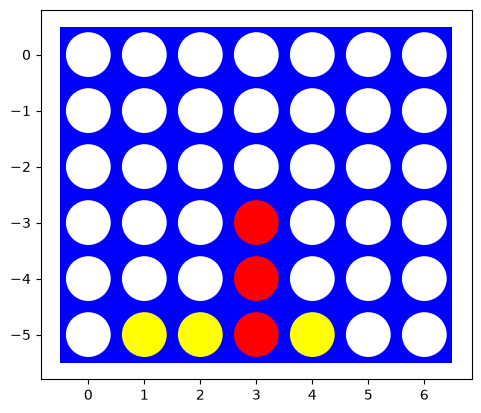

In [4]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [5]:
# Your code/ answer goes here.

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
# Your code/ answer goes here.

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
# Your code/ answer goes here.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [8]:
# Your code/ answer goes here.

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

In [9]:
# Your code/ answer goes here.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [10]:
# Your code/ answer goes here.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

In [11]:
# Your code/ answer goes here.

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [12]:
# Your code/ answer goes here.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [13]:
# Your code/ answer goes here.

## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [14]:
# Your code/ answer goes here.

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [15]:
# Your code/ answer goes here.

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [16]:
# Your code/ answer goes here.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [17]:
# Your code/ answer goes here.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

In [18]:
# Your code/ answer goes here.

## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [19]:
# Your code/ answer goes here.

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [20]:
# Your code/ answer goes here.